# code_181 · Marginally good outputs can form an invalid joint answer

**Book:** section 34.4. Restart and run all cells. All imports, helpers and generated inputs are internal. Ordinary execution requires no files, network, credentials or GPU. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_34_GUIDE.md), [execution evidence](../CHAPTER_34_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_181).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, Torch 2.14.1 CPU. Allow two minutes to run and 45–90 minutes to interpret. Original small implementations expose actual updates and controls; they are not benchmark reproductions or field causal conclusions. Target semantics, censoring or exposure, information roles and independent assessment are explicit. Generated records do not establish field performance or intervention validity. Original scoped mechanisms are identified separately from native library models.


In [1]:
import platform,time,json,copy,hashlib,itertools
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
import torch
from torch import nn
START=time.perf_counter();SEED=7581;rng=np.random.default_rng(SEED)
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__,'torch':torch.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0', 'torch': '2.14.1'}
CPU: Darwin arm64 seed: 7581


<a id="damage-label-dependence"></a>
 ## Predict a set of damage flags and check its validity
 Generate 1,000 source/200 development/400 final independent assets with four visible features. Corrosion depends on a spall flag as well as features, so labels have residual dependence. A third flag means neither spall nor corrosion. In this constructed task the allowed vectors are 001,100,010 and 110; this is a data-contract rule, not a universal statement that real damage types are incompatible. Fit independent logistic classifiers, a native classifier chain in the fixed order spall/corrosion/neither with five-fold cross-validated upstream predictions for fitting, and a shared 4→24→3 network with 600 BCE updates. Native chain predictions condition on earlier predicted flags, not unavailable final true labels; its probability scores are not advertised as an exact joint posterior. Settings and 0.5 thresholds are fixed, development remains diagnostic.

 For independent logistic and shared-head probabilities, enumerate allowed sets and maximize a product-Bernoulli score. This is a declared constrained decoding heuristic: it ensures validity while imposing an independent-score approximation. Do not call it learned joint MAP or apply that interpretation to chain conditionals. Report Hamming loss, micro-F 1, exact-vector accuracy and invalid-set fraction separately.


,model,Hamming_loss,micro_F1,exact_vector_accuracy,invalid_fraction
0,Independent,0.289167,0.676004,0.4700,0.1350
1,Chain,0.289167,0.676608,0.4625,0.1300
2,Shared,0.313333,0.648598,0.4450,0.1025
3,Ind projected,0.295833,0.683882,0.5125,0.0000
4,Shared projected,0.310833,0.662443,0.4775,0.0000


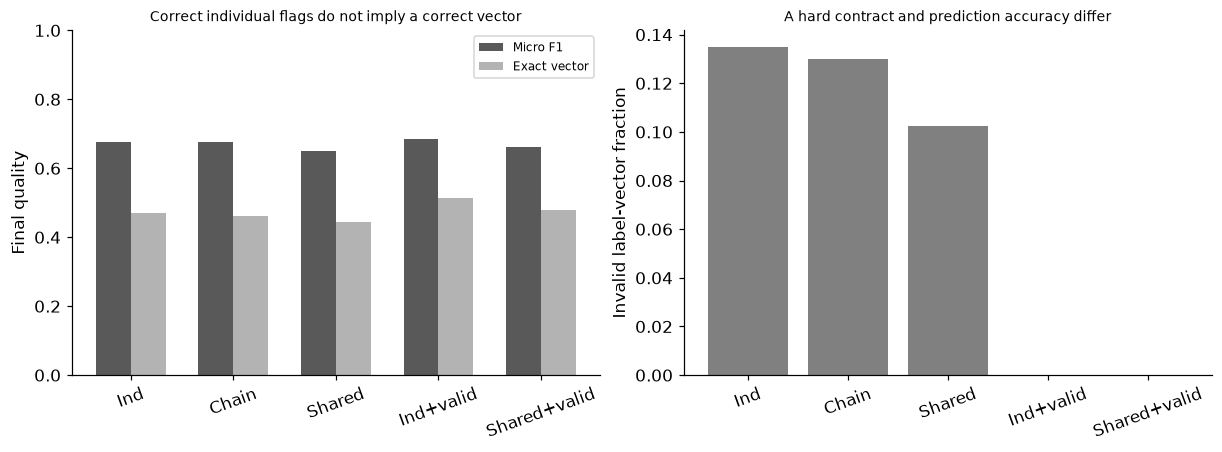

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.multioutput import MultiOutputClassifier,ClassifierChain
from sklearn.metrics import hamming_loss,f1_score,accuracy_score
def assets(n,gr):
    x=gr.normal(size=(n,4));spall=gr.random(n)<1/(1+np.exp(-(.9*x[:,0]+.5*x[:,1])));corrosion=gr.random(n)<1/(1+np.exp(-(.8*x[:,1]-.7*x[:,2]+1.6*spall-.6)));labels=np.c_[spall,corrosion,~(spall|corrosion)].astype(int);e=gr.normal(size=(n,2));a=3*x[:,0]+np.sin(x[:,1])+.25*e[:,0];b=-2*x[:,1]+.7*x[:,2]+.25*(.8*e[:,0]+.6*e[:,1]);displacement=np.c_[a,b,-a-b];return x,labels,displacement
SX,SY,SU=assets(1000,rng);DX,DY,DU=assets(200,rng);FX,FY,FU=assets(400,rng);ind=MultiOutputClassifier(LogisticRegression(max_iter=500)).fit(SX,SY);chain=ClassifierChain(LogisticRegression(max_iter=500),order=[0,1,2],cv=5,random_state=SEED).fit(SX,SY);label_net=nn.Sequential(nn.Linear(4,24),nn.Tanh(),nn.Linear(24,3));opt=torch.optim.Adam(label_net.parameters(),lr=.01)
for step in range(600):
    loss=nn.functional.binary_cross_entropy_with_logits(label_net(torch.tensor(SX)),torch.tensor(SY,dtype=torch.float64));opt.zero_grad();loss.backward();opt.step()
def independent_prob(x):return np.column_stack([p[:,1] for p in ind.predict_proba(x)])
def shared_prob(x):
    with torch.no_grad():return torch.sigmoid(label_net(torch.tensor(x))).numpy()
allowed=np.array([[0,0,1],[1,0,0],[0,1,0],[1,1,0]])
def project_labels(p):
    pp=np.clip(p,1e-8,1-1e-8);score=np.log(pp)@allowed.T+np.log1p(-pp)@(1-allowed).T;return allowed[np.argmax(score,1)]
def label_predictions(x):
    p=independent_prob(x);q=shared_prob(x);return {'Independent':(p>=.5).astype(int),'Chain':chain.predict(x).astype(int),'Shared':(q>=.5).astype(int),'Ind projected':project_labels(p),'Shared projected':project_labels(q)}
def label_metrics(x,y):
    rows=[]
    for name,pred in label_predictions(x).items():
        valid=np.any(np.all(pred[:,None,:]==allowed[None,:,:],axis=2),axis=1);rows.append({'model':name,'Hamming_loss':float(hamming_loss(y,pred)),'micro_F1':float(f1_score(y,pred,average='micro')),'exact_vector_accuracy':float(accuracy_score(y,pred)),'invalid_fraction':float(np.mean(~valid))})
    return rows
rows=label_metrics(FX,FY);dev=label_metrics(DX,DY);preds=label_predictions(FX);assert all(r['invalid_fraction']==0 for r in rows if 'projected' in r['model']);assert np.all(np.any(np.all(FY[:,None,:]==allowed[None,:,:],axis=2),axis=1)) and FX.shape[0]==400
RESULTS.update(source_assets=1000,development_assets=200,final_assets=400,allowed_label_vectors=allowed.tolist(),chain_order=[0,1,2],chain_upstream_folds=5,label_network_updates=600,final_label_metrics=rows,development_label_metrics=dev,development_used_for_selection=False)
display(pd.DataFrame(rows));fig,axes=plt.subplots(1,2,figsize=(11,4));names=['Ind','Chain','Shared','Ind+valid','Shared+valid'];axes[0].bar(np.arange(5)-.17,[r['micro_F1'] for r in rows],width=.34,label='Micro F1',color='.35');axes[0].bar(np.arange(5)+.17,[r['exact_vector_accuracy'] for r in rows],width=.34,label='Exact vector',color='.7');axes[0].set(xticks=range(5),xticklabels=names,ylim=(0,1),ylabel='Final quality',title='Correct individual flags do not imply a correct vector');axes[0].legend(fontsize=8);axes[1].bar(range(5),[r['invalid_fraction'] for r in rows],color='.5');axes[1].set(xticks=range(5),xticklabels=names,ylabel='Invalid label-vector fraction',title='A hard contract and prediction accuracy differ')
for ax in axes:ax.tick_params(axis='x',rotation=20)
plt.show()


<a id="correlated-continuous-outputs"></a>
 ## Fit correlated displacement components and enforce a stated relation
 The same generated assets have three signed displacements in millimetres. A fixture relation defines u 1+u 2+u 3=0 exactly, including the correlated generated disturbance. Fit three independent 80-tree depth 6 forests, one native multioutput 80-tree depth 6 forest sharing partitions, and a shared 4→24→3 network with 600 MSE updates. Independent trees may violate the relation because their fitted partitions differ; shared leaf averages of exact constrained targets preserve this linear relation up to rounding. Orthogonally subtract each vector's component mean as an explicit projection. Report component RMSE and mean absolute constraint residual before and after projection. This projection is justified only by the stated exact fixture rule, not by a claim about all structures or all boundary conditions.


,model,state,component_RMSE_mm,mean_absolute_sum_mm
0,Independent RF,Raw,0.546931,4.642054e-01
1,Independent RF,Projected,0.505112,1.800296e-16
2,Joint RF,Raw,0.663735,8.185379e-16
3,Joint RF,Projected,0.663735,1.672794e-16
4,Shared NN,Raw,0.373996,3.515531e-02
5,Shared NN,Projected,0.373606,1.493076e-16


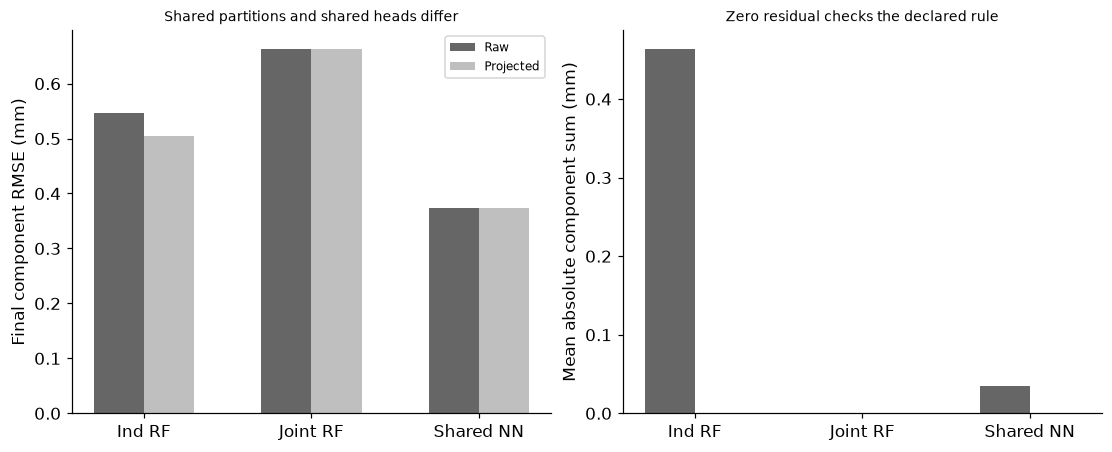

In [3]:
from sklearn.ensemble import RandomForestRegressor
independent_forests=[RandomForestRegressor(n_estimators=80,max_depth=6,n_jobs=1,random_state=SEED+j).fit(SX,SU[:,j]) for j in range(3)];joint_forest=RandomForestRegressor(n_estimators=80,max_depth=6,n_jobs=1,random_state=SEED).fit(SX,SU);vector_net=nn.Sequential(nn.Linear(4,24),nn.Tanh(),nn.Linear(24,3));opt=torch.optim.Adam(vector_net.parameters(),lr=.01)
for step in range(600):
    loss=nn.functional.mse_loss(vector_net(torch.tensor(SX)),torch.tensor(SU));opt.zero_grad();loss.backward();opt.step()
with torch.no_grad():neural_vector=vector_net(torch.tensor(FX)).numpy()
vectors={'Independent RF':np.column_stack([m.predict(FX) for m in independent_forests]),'Joint RF':joint_forest.predict(FX),'Shared NN':neural_vector};vector_rows=[];projected={}
for name,pred in vectors.items():
    projected[name]=pred-pred.mean(1,keepdims=True)
    for state,value in [('Raw',pred),('Projected',projected[name])]:vector_rows.append({'model':name,'state':state,'component_RMSE_mm':float(np.sqrt(np.mean((value-FU)**2))),'mean_absolute_sum_mm':float(np.mean(np.abs(value.sum(1))))})
    assert np.max(np.abs(projected[name].sum(1)))<1e-10
    assert np.mean((projected[name]-FU)**2)<=np.mean((pred-FU)**2)+1e-12
assert np.max(np.abs(FU.sum(1)))<1e-12 and np.max(np.abs(vectors['Joint RF'].sum(1)))<1e-10
RESULTS.update(displacement_relation='u1+u2+u3=0 mm in the declared fixture',forest_trees_each=80,forest_depth=6,vector_network_updates=600,final_vector_metrics=vector_rows,shared_RF_preserves_linear_relation=True)
display(pd.DataFrame(vector_rows));fig,axes=plt.subplots(1,2,figsize=(10,4))
for j,state in enumerate(['Raw','Projected']):
    r=[v for v in vector_rows if v['state']==state];axes[0].bar(np.arange(3)+(j-.5)*.3,[v['component_RMSE_mm'] for v in r],width=.3,color=['.4','.75'][j],label=state);axes[1].bar(np.arange(3)+(j-.5)*.3,[v['mean_absolute_sum_mm'] for v in r],width=.3,color=['.4','.75'][j],label=state)
for ax in axes:ax.set_xticks(range(3),['Ind RF','Joint RF','Shared NN'])
axes[0].set(ylabel='Final component RMSE (mm)',title='Shared partitions and shared heads differ');axes[1].set(ylabel='Mean absolute component sum (mm)',title='Zero residual checks the declared rule');axes[0].legend(fontsize=8);plt.show()


<a id="same-entities-different-output-structures"></a>
 ## Inspect one ordered list, several flags and a constrained vector
 Use the fixed first six final assets, ordered by the independent model's sum of spall and corrosion probabilities. This is a declared illustrative score, not a reused trained inspection policy or calibrated probability of any damage. Show projected damage flags and projected independent-forest displacements for these same assets. The ordering determines a priority list; the label set and signed vector answer different questions. Neither a valid combination nor a small zero-sum residual establishes a correct field prediction.


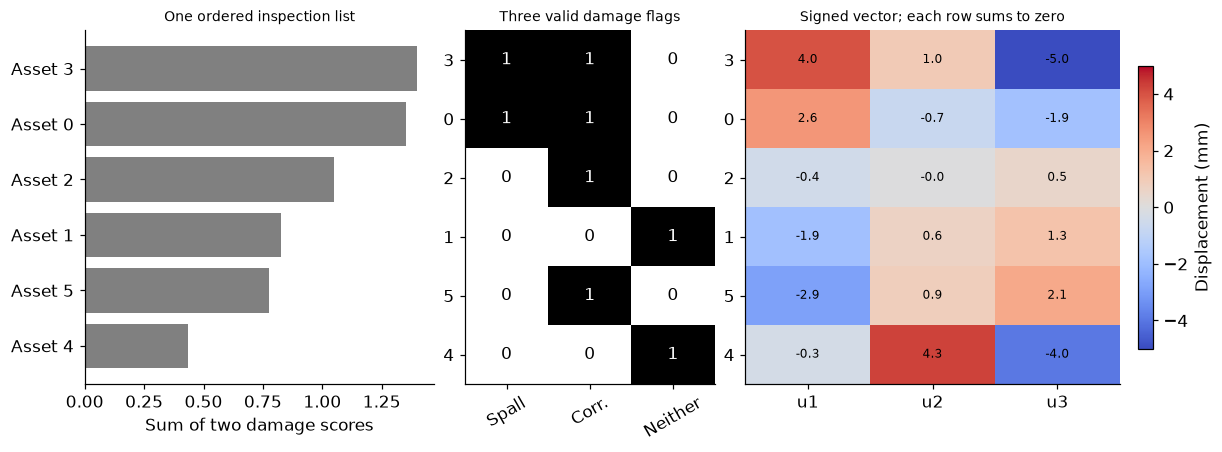

In [4]:
fixed=np.arange(6);priority=independent_prob(FX[fixed])[:,:2].sum(1);ordered=fixed[np.argsort(-priority)];flags=preds['Ind projected'][ordered];disp=projected['Independent RF'][ordered];assert len(set(ordered))==6 and np.max(np.abs(disp.sum(1)))<1e-10
RESULTS.update(illustration_final_asset_ids=ordered.tolist(),illustration_priority_scores=priority[np.argsort(-priority)].tolist(),illustration_damage_flags=flags.tolist(),illustration_displacements_mm=disp.tolist())
fig,axes=plt.subplots(1,3,figsize=(11,4),gridspec_kw={'width_ratios':[1.4,1,1.5]});axes[0].barh(np.arange(6),priority[np.argsort(-priority)],color='.5');axes[0].invert_yaxis();axes[0].set(yticks=range(6),yticklabels=[f'Asset {j}' for j in ordered],xlabel='Sum of two damage scores',title='One ordered inspection list');axes[1].imshow(flags,cmap='Greys',vmin=0,vmax=1,aspect='auto');axes[1].set(xticks=range(3),xticklabels=['Spall','Corr.','Neither'],yticks=range(6),yticklabels=[str(j) for j in ordered],title='Three valid damage flags');axes[1].tick_params(axis='x',rotation=30)
for row in range(6):
    for col in range(3):axes[1].text(col,row,str(flags[row,col]),ha='center',va='center',color='white' if flags[row,col] else 'black')
lim=float(np.max(np.abs(disp)));im=axes[2].imshow(disp,cmap='coolwarm',vmin=-lim,vmax=lim,aspect='auto');axes[2].set(xticks=range(3),xticklabels=['u1','u2','u3'],yticks=range(6),yticklabels=[str(j) for j in ordered],title='Signed vector; each row sums to zero')
for row in range(6):
    for col in range(3):axes[2].text(col,row,f'{disp[row,col]:.1f}',ha='center',va='center',fontsize=8)
fig.colorbar(im,ax=axes[2],label='Displacement (mm)',shrink=.8);plt.show()


In [5]:
summary={'example_id':'code_181','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['native independent logistic labels and fivefold out-of-fold classifier chains', 'actual shared neural label heads and explicit valid-set projection', 'independent versus shared-partition forests and neural vector heads', 'orthogonal displacement projection under a declared fixture relation', 'same-entity ranked list multilabel matrix and constrained vector visualization'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["native independent logistic labels and fivefold out-of-fold classifier chains", "actual shared neural label heads and explicit valid-set projection", "independent versus shared-partition forests and neural vector heads", "orthogonal displacement projection under a declared fixture relation", "same-entity ranked list multilabel matrix and constrained vector visualization"], "elapsed_seconds": 1.325, "example_id": "code_181", "hardware": "Darwin arm64 CPU", "results": {"allowed_label_vectors": [[0, 0, 1], [1, 0, 0], [0, 1, 0], [1, 1, 0]], "chain_order": [0, 1, 2], "chain_upstream_folds": 5, "development_assets": 200, "development_label_metrics": [{"Hamming_loss": 0.305, "exact_vector_accuracy": 0.425, "invalid_fraction": 0.155, "micro_F1": 0.6500956022944551, "model": "Independent"}, {"Hamming_loss": 0.295, "exact_vector_accuracy": 0.445, "invalid_fraction": 0.145, "micro_F1": 0.6602687140115163, "model": "Chain"}, {"Hamming_loss": 0.365